**Part-1**

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

reg_df = pd.read_csv("Movie_regression.csv")
clf_df = pd.read_csv("Movie_classification.csv")




In [73]:
print("Regression Dataset Shape:", reg_df.shape)
print("Classification Dataset Shape:", clf_df.shape)

Regression Dataset Shape: (506, 18)
Classification Dataset Shape: (506, 19)


regression part eda

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Marketing expense    506 non-null    float64
 1   Production expense   506 non-null    float64
 2   Multiplex coverage   506 non-null    float64
 3   Budget               506 non-null    float64
 4   Movie_length         506 non-null    float64
 5   Lead_ Actor_Rating   506 non-null    float64
 6   Lead_Actress_rating  506 non-null    float64
 7   Director_rating      506 non-null    float64
 8   Producer_rating      506 non-null    float64
 9   Critic_rating        506 non-null    float64
 10  Trailer_views        506 non-null    int64  
 11  3D_available         506 non-null    object 
 12  Time_taken           494 non-null    float64
 13  Twitter_hastags      506 non-null    float64
 14  Genre                506 non-null    object 
 15  Avg_age_actors       506 non-null    int

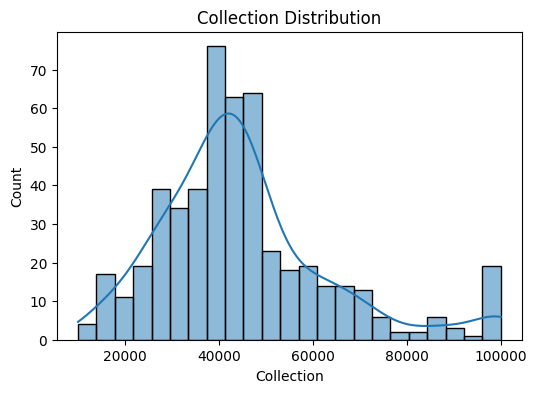

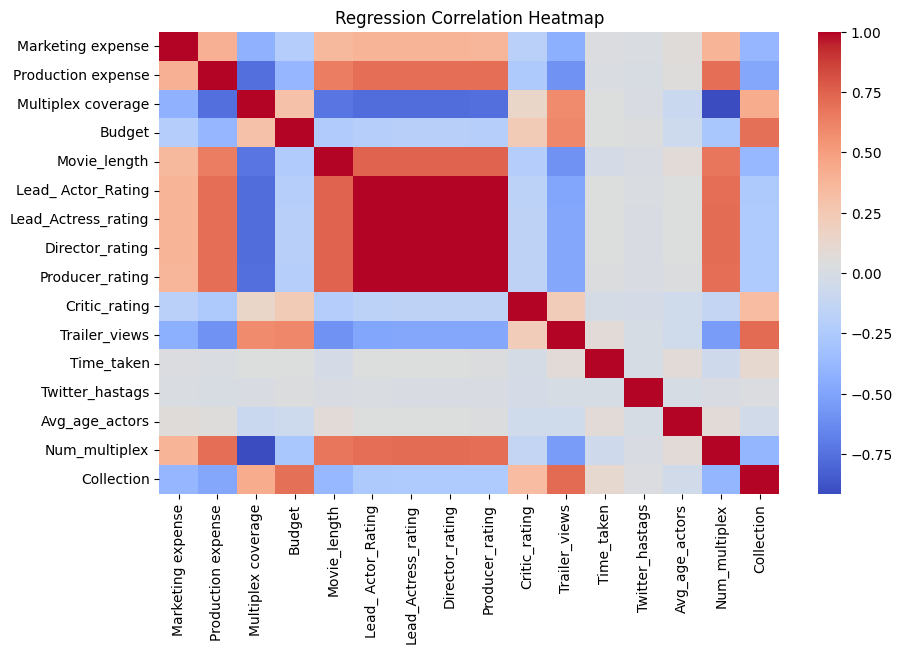

In [74]:
print(reg_df.info())
print("\nMissing Values:")
print(reg_df.isnull().sum())

print("\nDuplicate Rows:")
print(reg_df.duplicated().sum())

print("\nSummary Statistics:")
print(reg_df.describe())

# Target Distribution
plt.figure(figsize=(6,4))
sns.histplot(reg_df["Collection"], kde=True)
plt.title("Collection Distribution")
plt.show()

# Correlation Heatmap
plt.figure(figsize=(10,6))
sns.heatmap(reg_df.corr(numeric_only=True),
            cmap="coolwarm")
plt.title("Regression Correlation Heatmap")
plt.show()

classification part eda

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Marketing expense    506 non-null    float64
 1   Production expense   506 non-null    float64
 2   Multiplex coverage   506 non-null    float64
 3   Budget               506 non-null    float64
 4   Movie_length         506 non-null    float64
 5   Lead_ Actor_Rating   506 non-null    float64
 6   Lead_Actress_rating  506 non-null    float64
 7   Director_rating      506 non-null    float64
 8   Producer_rating      506 non-null    float64
 9   Critic_rating        506 non-null    float64
 10  Trailer_views        506 non-null    int64  
 11  3D_available         506 non-null    object 
 12  Time_taken           494 non-null    float64
 13  Twitter_hastags      506 non-null    float64
 14  Genre                506 non-null    object 
 15  Avg_age_actors       506 non-null    int

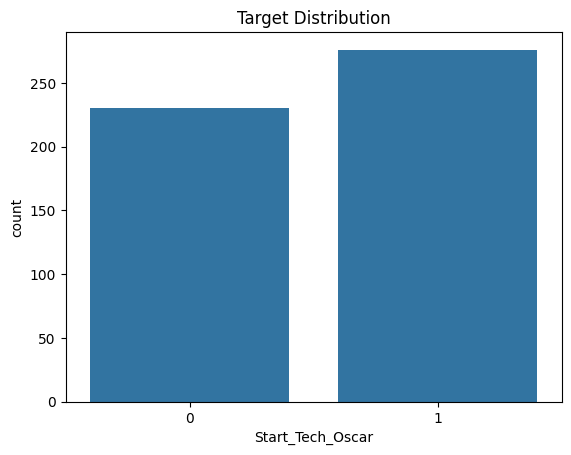

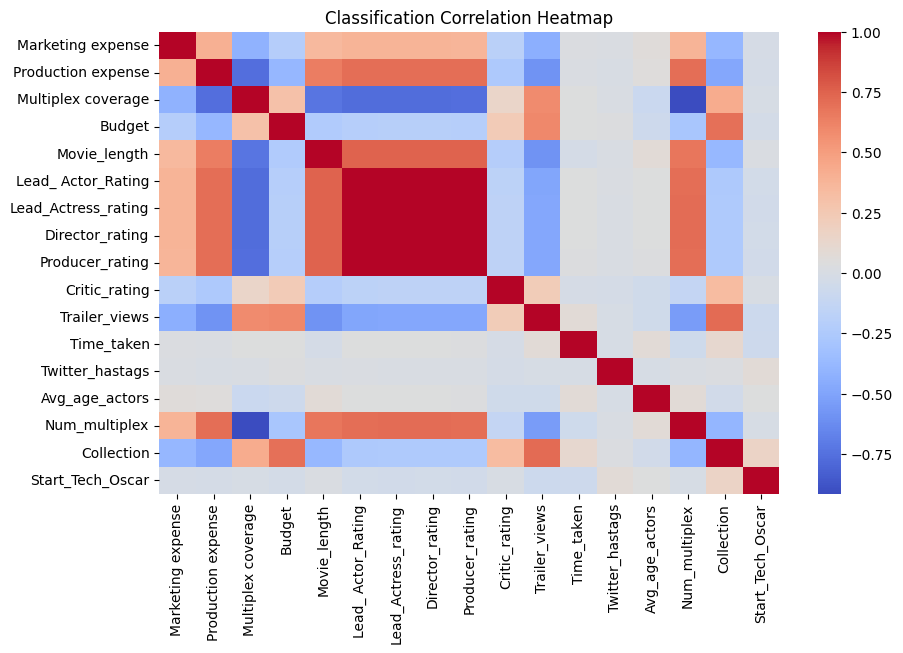

In [75]:
print(clf_df.info())

print("\nMissing Values:")
print(clf_df.isnull().sum())

print("\nDuplicate Rows:")
print(clf_df.duplicated().sum())

print("\nSummary Statistics:")
print(clf_df.describe())

# Target Distribution
sns.countplot(x="Start_Tech_Oscar", data=clf_df)
plt.title("Target Distribution")
plt.show()

# Correlation Heatmap
plt.figure(figsize=(10,6))
sns.heatmap(clf_df.corr(numeric_only=True),
            cmap="coolwarm")
plt.title("Classification Correlation Heatmap")
plt.show()

In [76]:
reg_df = reg_df.dropna() # Handle Missing Values
clf_df = clf_df.dropna() # Handle Missing Values

y_reg = reg_df["Collection"] # Target Variables
y_clf = clf_df["Start_Tech_Oscar"] # Target Variables

X_reg = reg_df.drop("Collection", axis=1)
X_clf = clf_df.drop("Start_Tech_Oscar", axis=1)

X_reg = pd.get_dummies(X_reg, drop_first=True) # One-Hot Encoding
X_clf = pd.get_dummies(X_clf, drop_first=True) # One-Hot Encoding
print(X_reg.shape)
print(X_clf.shape)

(494, 19)
(494, 20)


In [77]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg,
    test_size=0.20,
    random_state=42
)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf,
    test_size=0.20,
    random_state=42,
    stratify=y_clf
)

adding the model

In [78]:
reg_model = DecisionTreeRegressor(random_state=42)
clf_model = DecisionTreeClassifier(random_state=42)

reg_model.fit(Xr_train, yr_train)
clf_model.fit(Xc_train, yc_train)

DecisionTreeClassifier(random_state=42)

regression

In [79]:
reg_pred = reg_model.predict(Xr_test)

mae = mean_absolute_error(yr_test, reg_pred)
mse = mean_squared_error(yr_test, reg_pred)
rmse = np.sqrt(mse)
r2 = r2_score(yr_test, reg_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 5789.89898989899
MSE : 58044444.44444445
RMSE: 7618.690467819548
R2  : 0.7610955705066682


classification

In [80]:
clf_pred = clf_model.predict(Xc_test)

acc = accuracy_score(yc_test, clf_pred)
prec = precision_score(yc_test, clf_pred)
rec = recall_score(yc_test, clf_pred)
f1 = f1_score(yc_test, clf_pred)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1 Score :", f1)

print("\nClassification Report")
print(classification_report(yc_test, clf_pred))

Accuracy : 0.6161616161616161
Precision: 0.6481481481481481
Recall   : 0.6481481481481481
F1 Score : 0.6481481481481481

Classification Report
              precision    recall  f1-score   support

           0       0.58      0.58      0.58        45
           1       0.65      0.65      0.65        54

    accuracy                           0.62        99
   macro avg       0.61      0.61      0.61        99
weighted avg       0.62      0.62      0.62        99



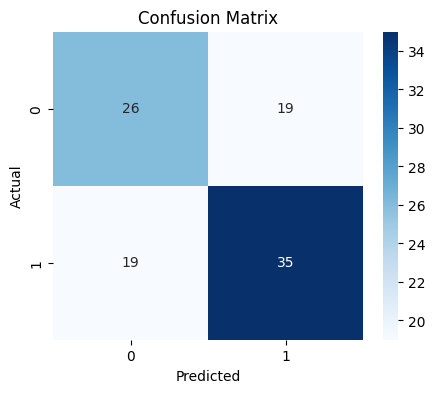

In [81]:
cm = confusion_matrix(yc_test, clf_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

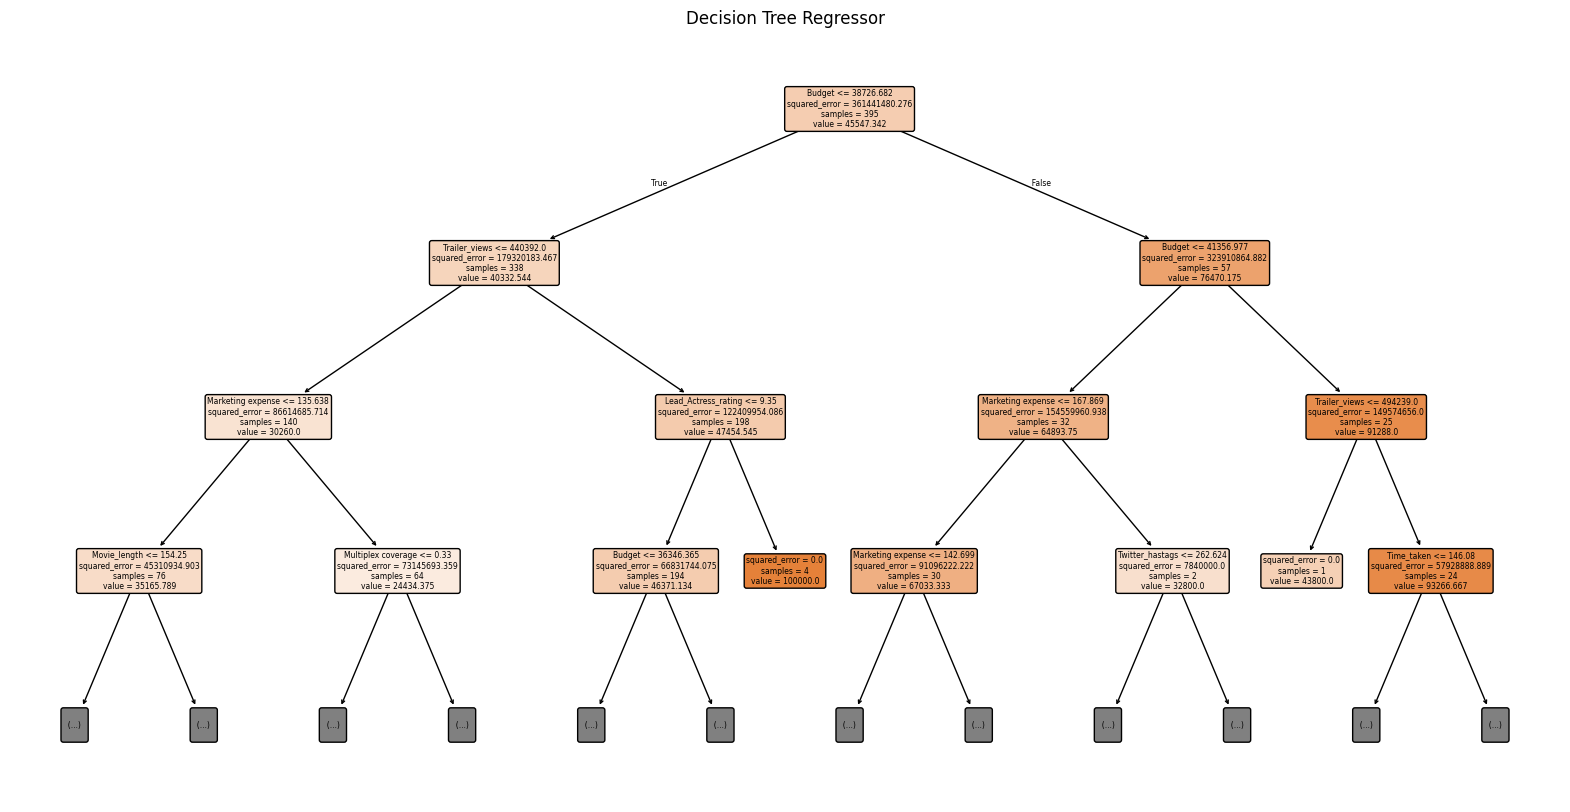

In [82]:
plt.figure(figsize=(20,10))

plot_tree(
    reg_model,
    feature_names=X_reg.columns,
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title("Decision Tree Regressor")
plt.show()

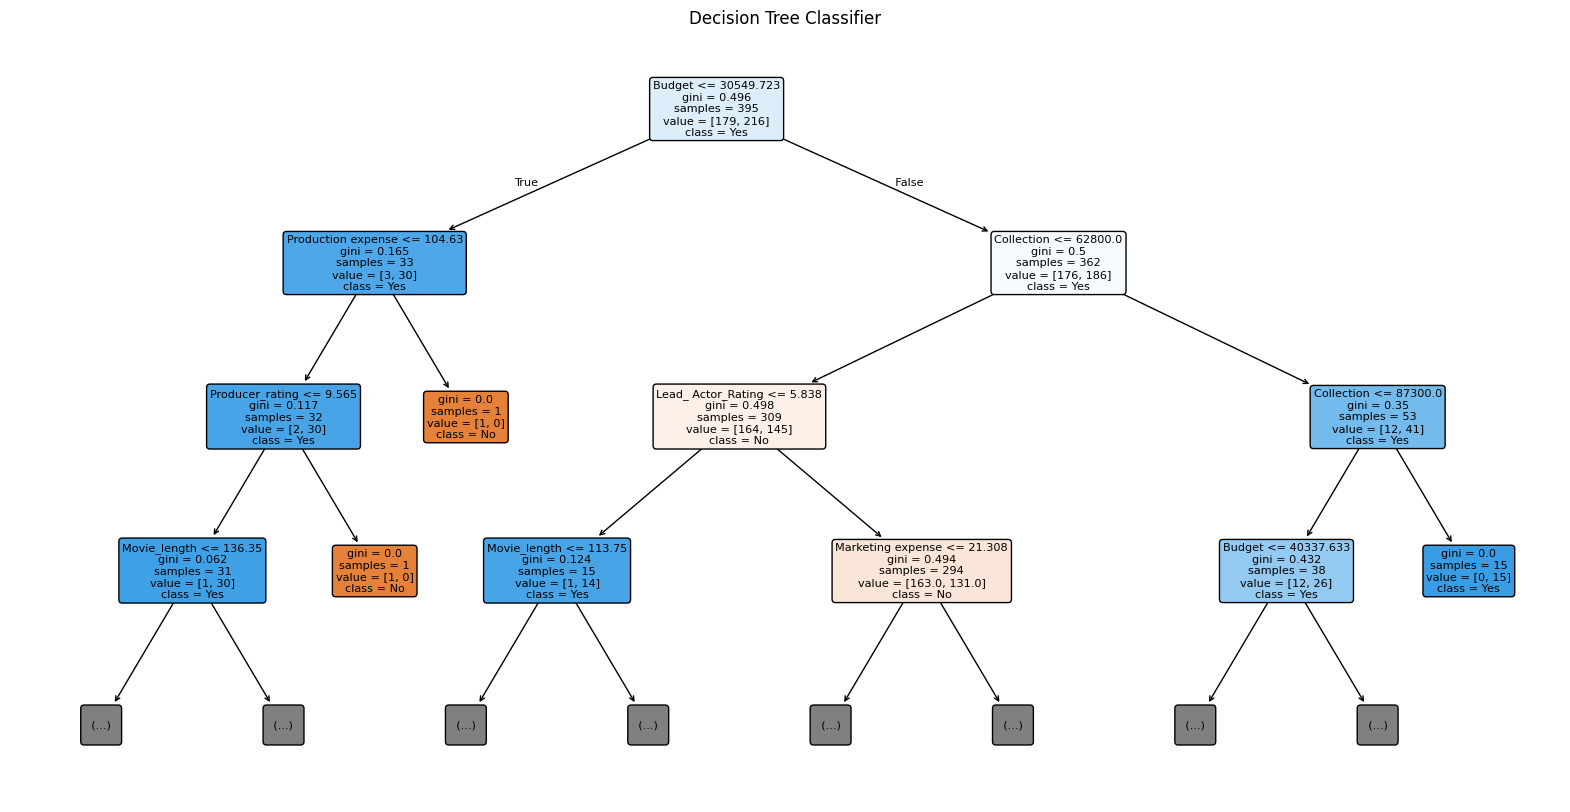

In [83]:
plt.figure(figsize=(20,10))

plot_tree(
    clf_model,
    feature_names=X_clf.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title("Decision Tree Classifier")
plt.show()

In [84]:
print("Regression Tree Depth :", reg_model.get_depth())
print("Regression Leaves     :", reg_model.get_n_leaves())

print("Classification Tree Depth :", clf_model.get_depth())
print("Classification Leaves     :", clf_model.get_n_leaves())

Regression Tree Depth : 20
Regression Leaves     : 366
Classification Tree Depth : 17
Classification Leaves     : 79


In [85]:
print("Train R²:", reg_model.score(Xr_train, yr_train))
print("Test R² :", reg_model.score(Xr_test, yr_test))

Train R²: 1.0
Test R² : 0.7610955705066682


1. What was the train score and test score for Decision Tree Regression?
Test Score (R²) = 0.7611
Train Score  (R²)= 1

2. indicating overfitting.

In [86]:
print("Depth:", reg_model.get_depth())
print("Depth:", clf_model.get_depth())

Depth: 20
Depth: 17


**Part-2**

**Pre-Pruning**

regression metrics

In [87]:
reg_pruned = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_leaf_nodes=20,
    random_state=42
)

reg_pruned.fit(Xr_train, yr_train)

reg_pred_pruned = reg_pruned.predict(Xr_test)

In [88]:
mae_pruned = mean_absolute_error(yr_test, reg_pred_pruned)
mse_pruned = mean_squared_error(yr_test, reg_pred_pruned)
rmse_pruned = np.sqrt(mse_pruned)
r2_pruned = r2_score(yr_test, reg_pred_pruned)

print("MAE :", mae_pruned)
print("MSE :", mse_pruned)
print("RMSE:", rmse_pruned)
print("R2 :", r2_pruned)

print("Depth :", reg_pruned.get_depth())
print("Leaves :", reg_pruned.get_n_leaves())

MAE : 5199.817919586189
MSE : 41098392.19611223
RMSE: 6410.802773140992
R2 : 0.8308436227673267
Depth : 5
Leaves : 20


classification metrics

In [89]:
clf_pruned = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_leaf_nodes=20,
    random_state=42
)

clf_pruned.fit(Xc_train, yc_train)

clf_pred_pruned = clf_pruned.predict(Xc_test)

In [90]:
print("Accuracy:",
      accuracy_score(yc_test, clf_pred_pruned))

print("Precision:",
      precision_score(yc_test, clf_pred_pruned))

print("Recall:",
      recall_score(yc_test, clf_pred_pruned))

print("F1:",
      f1_score(yc_test, clf_pred_pruned))

print(confusion_matrix(yc_test, clf_pred_pruned))

print("Depth:", clf_pruned.get_depth())
print("Leaves:", clf_pruned.get_n_leaves())

Accuracy: 0.5959595959595959
Precision: 0.675
Recall: 0.5
F1: 0.574468085106383
[[32 13]
 [27 27]]
Depth: 5
Leaves: 14


comparing unpruned & pruned

In [91]:
comparison_reg = pd.DataFrame({
    "Metric":["MAE","MSE","RMSE","R2"],
    "Unpruned":[mae,mse,rmse,r2],
    "Pruned":[mae_pruned,mse_pruned,rmse_pruned,r2_pruned]
})

print(comparison_reg)

  Metric      Unpruned        Pruned
0    MAE  5.789899e+03  5.199818e+03
1    MSE  5.804444e+07  4.109839e+07
2   RMSE  7.618690e+03  6.410803e+03
3     R2  7.610956e-01  8.308436e-01


**Post-Pruning**

regression

In [92]:
path = reg_model.cost_complexity_pruning_path(
    Xr_train,
    yr_train
)

ccp_alphas = path.ccp_alphas

models = []

for alpha in ccp_alphas:
    model = DecisionTreeRegressor(
        random_state=42,
        ccp_alpha=alpha
    )

    model.fit(Xr_train, yr_train)
    models.append(model)

train_scores = [
    m.score(Xr_train, yr_train)
    for m in models
]

test_scores = [
    m.score(Xr_test, yr_test)
    for m in models
]

best_index = np.argmax(test_scores)

best_reg = models[best_index]

print("Best Alpha:", ccp_alphas[best_index])
print("Train Score:", train_scores[best_index])
print("Test Score :", test_scores[best_index])
print("Leaves:", best_reg.get_n_leaves())

Best Alpha: 1868492.8863335531
Train Score: 0.8981086468412142
Test Score : 0.8102102732247236
Leaves: 14


classification

In [93]:
path = clf_model.cost_complexity_pruning_path(
    Xc_train,
    yc_train
)

ccp_alphas = path.ccp_alphas

models = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    model.fit(Xc_train, yc_train)
    models.append(model)

train_scores = [
    m.score(Xc_train, yc_train)
    for m in models
]

test_scores = [
    m.score(Xc_test, yc_test)
    for m in models
]

best_index = np.argmax(test_scores)

best_clf = models[best_index]

print("Best Alpha:", ccp_alphas[best_index])
print("Train Score:", train_scores[best_index])
print("Test Score :", test_scores[best_index])
print("Leaves:", best_clf.get_n_leaves())

Best Alpha: 0.005890944498539435
Train Score: 0.8810126582278481
Test Score : 0.6767676767676768
Leaves: 33


**K fold Cross-validation**
Using 5-fold cross-validation.

regression

In [94]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    best_reg,
    X_reg,
    y_reg,
    cv=5,
    scoring='r2'
)

print("CV Scores:", cv_scores)
print("Average CV Score:", cv_scores.mean())

CV Scores: [0.72297351 0.6022448  0.75676348 0.36266856 0.03455835]
Average CV Score: 0.49584173780413365


classification

In [95]:
cv_scores = cross_val_score(
    best_clf,
    X_clf,
    y_clf,
    cv=5,
    scoring='accuracy'
)

print("CV Scores:", cv_scores)
print("Average CV Score:", cv_scores.mean())

CV Scores: [0.52525253 0.56565657 0.46464646 0.64646465 0.62244898]
Average CV Score: 0.5648938363224077


**Grid Search CV**

regression

In [96]:
param_grid = {
    'max_depth':[3,5,7,10],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,5],
    'max_leaf_nodes':[10,20,30]
}

grid_reg = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring='r2'
)

grid_reg.fit(Xr_train, yr_train)

print("Best Parameters:")
print(grid_reg.best_params_)

print("Best CV Score:")
print(grid_reg.best_score_)

Best Parameters:
{'max_depth': 5, 'max_leaf_nodes': 30, 'min_samples_leaf': 2, 'min_samples_split': 10}
Best CV Score:
0.7571837558216761


classification

In [97]:
param_grid = {
    'max_depth':[3,5,7,10],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,5],
    'max_leaf_nodes':[10,20,30]
}

grid_clf = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid_clf.fit(Xc_train, yc_train)

print("Best Parameters:")
print(grid_clf.best_params_)

print("Best CV Score:")
print(grid_clf.best_score_)

Best Parameters:
{'max_depth': 7, 'max_leaf_nodes': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV Score:
0.5974683544303797


In [98]:
best_model = grid_reg.best_estimator_

pred = best_model.predict(Xr_test)

print("Final R2:",
      r2_score(yr_test, pred))

print("Final RMSE:",
      np.sqrt(mean_squared_error(
          yr_test,
          pred
      )))

Final R2: 0.7909868038140618
Final RMSE: 7126.152001030106


In [99]:
best_model = grid_clf.best_estimator_

pred = best_model.predict(Xc_test)

print("Final Accuracy:",
      accuracy_score(
          yc_test,
          pred
      ))

print(classification_report(
    yc_test,
    pred
))

Final Accuracy: 0.6464646464646465
              precision    recall  f1-score   support

           0       0.66      0.47      0.55        45
           1       0.64      0.80      0.71        54

    accuracy                           0.65        99
   macro avg       0.65      0.63      0.63        99
weighted avg       0.65      0.65      0.64        99



Part 4 XGBoost

In [100]:
from xgboost import XGBRegressor, XGBClassifier
!pip install xgboost

**Regression**

train xgboost regressor

In [101]:
xgb_reg = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

xgb_reg.fit(Xr_train, yr_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

prediction

In [102]:
xgb_pred = xgb_reg.predict(Xr_test)

regression metrics

In [103]:
xgb_mae = mean_absolute_error(yr_test, xgb_pred)
xgb_mse = mean_squared_error(yr_test, xgb_pred)
xgb_rmse = np.sqrt(xgb_mse)
xgb_r2 = r2_score(yr_test, xgb_pred)

print("XGBoost Regression")

print("MAE :", xgb_mae)
print("MSE :", xgb_mse)
print("RMSE:", xgb_rmse)
print("R2 :", xgb_r2)

XGBoost Regression
MAE : 4105.82568359375
MSE : 28462880.0
RMSE: 5335.061386713372
R2 : 0.8828499913215637


**Classification**

train xgboost classifier

In [104]:
xgb_clf = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)

xgb_clf.fit(Xc_train, yc_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

Prediction

In [105]:
xgb_pred = xgb_clf.predict(Xc_test)

In [106]:
print("Accuracy :", accuracy_score(yc_test, xgb_pred))
print("Precision :", precision_score(yc_test, xgb_pred))
print("Recall :", recall_score(yc_test, xgb_pred))
print("F1 Score :", f1_score(yc_test, xgb_pred))
print()
print(classification_report(yc_test, xgb_pred))
print()
print(confusion_matrix(yc_test, xgb_pred))

Accuracy : 0.6161616161616161
Precision : 0.625
Recall : 0.7407407407407407
F1 Score : 0.6779661016949152

              precision    recall  f1-score   support

           0       0.60      0.47      0.53        45
           1       0.62      0.74      0.68        54

    accuracy                           0.62        99
   macro avg       0.61      0.60      0.60        99
weighted avg       0.61      0.62      0.61        99


[[21 24]
 [14 40]]


Regression Comparision

In [107]:
comparison_reg = pd.DataFrame({

"Model":[
"Unpruned DT",
"Pre-Pruned DT",
"Post-Pruned DT",
"Cross Validation DT",
"XGBoost"
],

"RMSE":[
rmse,
rmse_pruned,
rmse,
7126.152001030106,
xgb_rmse
],

"MAE":[
mae,
mae_pruned,
mae,
mae,
xgb_mae
],

"R2":[
r2,
r2_pruned,
0.8102102732247236,
0.7909868038140618,
xgb_r2
]

})

comparison_reg

,Model,RMSE,MAE,R2
0,Unpruned DT,7618.690468,5789.898990,0.761096
1,Pre-Pruned DT,6410.802773,5199.817920,0.830844
2,Post-Pruned DT,7618.690468,5789.898990,0.810210
3,Cross Validation DT,7126.152001,5789.898990,0.790987
4,XGBoost,5335.061387,4105.825684,0.882850


Classification Comparison

In [108]:
comparison_reg = pd.DataFrame({

"Model":[
"Unpruned DT",
"Pre-Pruned DT",
"Post-Pruned DT",
"Cross Validation DT",
"XGBoost"
],

"RMSE":[
rmse,
rmse_pruned,
rmse,
7126.152001030106,
xgb_rmse
],

"MAE":[
mae,
mae_pruned,
mae,
mae,
xgb_mae
],

"R2":[
r2,
r2_pruned,
0.8102102732247236,
0.7909868038140618,
xgb_r2
]

})

comparison_reg

,Model,RMSE,MAE,R2
0,Unpruned DT,7618.690468,5789.898990,0.761096
1,Pre-Pruned DT,6410.802773,5199.817920,0.830844
2,Post-Pruned DT,7618.690468,5789.898990,0.810210
3,Cross Validation DT,7126.152001,5789.898990,0.790987
4,XGBoost,5335.061387,4105.825684,0.882850


Regression vs Classification

In [109]:
print("Regression")
print(comparison_reg)
print("Classification")
print(comparison_clf)

Regression
                 Model         RMSE          MAE        R2
0          Unpruned DT  7618.690468  5789.898990  0.761096
1        Pre-Pruned DT  6410.802773  5199.817920  0.830844
2       Post-Pruned DT  7618.690468  5789.898990  0.810210
3  Cross Validation DT  7126.152001  5789.898990  0.790987
4              XGBoost  5335.061387  4105.825684  0.882850
Classification
                 Model  Accuracy  Precision    Recall        F1
0          Unpruned DT  0.616162   0.648148  0.648148  0.648148
1        Pre-Pruned DT  0.595960   0.675000  0.500000  0.574468
2       Post-Pruned DT  0.676768   0.648148  0.648148  0.648148
3  Cross Validation DT  0.646465   0.648148  0.648148  0.648148
4              XGBoost  0.616162   0.625000  0.740741  0.677966


Part A: Questions After Basic Decision Tree Training
1. What was the train score and test score for Decision Tree Regression?

The Decision Tree Regressor achieved a training R² score of 1.00 and a testing R² score of 0.7611. The perfect training score shows that the model learned the training data very well, while the lower testing score indicates that its performance decreased on unseen data.

2. Was the training error much lower than the testing error?

Yes. The training error was much lower than the testing error. This happened because the model fitted the training data almost perfectly but could not perform equally well on new data.

3. Did the tree become too deep?

Yes. The regression tree reached a depth of 20, and the classification tree reached a depth of 17. These are relatively large depths, showing that the trees became very complex.

4. How many leaf nodes were created?

The regression tree created 366 leaf nodes, while the classification tree created 79 leaf nodes. Such a large number of leaves increases the complexity of the model.

5. Did you observe small leaves with very few samples?

Yes. Many leaf nodes contained only a small number of samples. This usually indicates that the model is memorizing the training data instead of learning general patterns.

6. In the regression tree, which feature appeared near the root node?

The Budget feature appeared near the root of the regression tree. Since it was selected as one of the first splitting variables, it had a strong influence on predicting the movie collection.

7. In the classification tree, which features appeared important?

The classification tree mainly used Budget, Collection, Lead Actor Rating, and Multiplex Coverage for making predictions. These features played the most important role in deciding whether a movie would receive the Oscar label.

8. Did the unpruned tree look easy to explain to a business user?

No. The unpruned tree contained many levels and branches, making it difficult for a business user to understand the decision-making process. A smaller tree would be much easier to explain.

9. Was the model overfitting, underfitting, or generalizing well?

The model was overfitting. This is evident because the training score was perfect (1.00), while the testing score was noticeably lower (0.7611). The model learned the training data too closely and did not generalize equally well to unseen data.

10. What metric did you trust more: train score or test score? Why?

I trust the test score more because it measures the model's performance on unseen data. It gives a more realistic estimate of how the model will perform in practical applications.

Part B: Think Before Improving
1. If the tree is too deep, which hyperparameter can control it?

 max_depth

2. If the tree has very small leaf nodes, which hyperparameter can control it?

 min_samples_leaf

3. If we want only a limited number of business segments, which hyperparameter can control it?

 max_leaf_nodes

4. Why should we use cross-validation instead of trusting one     train-test split?
Cross-validation uses multiple data splits and provides a more reliable estimate of model performance.

5. Why might XGBoost perform better than a single Decision Tree?
XGBoost combines many trees, reduces errors, prevents overfitting, and usually gives better prediction accuracy.